# 3.3 Tratamento e pré-processamento

Este notebook reproduz e documenta o **protocolo diário atual**, empregado em `teste_cronos_diario.ipynb`, com a base brasileira reconstruída pelos contadores. Complementa o notebook [3.2: Dados originais](03_02_caracterizacao_dados_crus.ipynb).

As cinco subseções seguem a estrutura do TCC. As operações existentes são refeitas em memória e comparadas numericamente com os arquivos usados no experimento. Não se regravam bases, não se treinam modelos e não se mudam alvos ou partições. Resultados de versões anteriores da base brasileira não são misturados aos desta versão.

Execute do início ao fim usando um kernel Python com as dependências do projeto. As oito figuras são incorporadas às saídas e exportadas em PNG (300 dpi) e PDF vetorial em `reports/tcc/preprocessamento_diario/figuras/`. Tabelas completas, legendas e hashes dos arquivos acompanham as imagens.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
from IPython.display import display, Image, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/energia_transfer").is_dir() and (p / "data/raw").is_dir())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from energia_transfer.preprocessamento_tcc import preparar_preprocessamento, gerar_figuras_preprocessamento

pd.set_option("display.max_columns", 16)
pd.set_option("display.float_format", lambda v: f"{v:.5f}")
processamento = preparar_preprocessamento(RAIZ)
indice = gerar_figuras_preprocessamento(processamento)
tabelas = processamento["tabelas"]
PASTA = processamento["pasta"]

def figura(numero):
    item = indice[numero-1]
    display(Image(filename=str(processamento["figuras"] / (item["arquivo"] + ".png")), width=1050))
    display(Markdown(f"**Figura 3.3-{numero:02d}: {item['titulo']}.** {item['legenda']}\n\n"
                     "Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto."))

print("Reconstruções e arquivos do experimento conferidos numericamente.")
print("Relatórios:", PASTA)
print(f"Figuras: {len(indice)} PNG + {len(indice)} PDF")

Reconstruções e arquivos do experimento conferidos numericamente.
Relatórios: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\preprocessamento_diario
Figuras: 8 PNG + 8 PDF


## 3.3.1 Tratamento da base australiana

1. Interpretar e ordenar os timestamps na convenção do CSV, sem conversão para o fuso brasileiro.
2. Calcular médias diárias das leituras disponíveis e recortar até **31/12/2023**. O notebook 3.2 caracteriza o arquivo integral, até 2025; este recorte pertence ao experimento, não à coleta original.
3. Completar o calendário diário, mantendo os dias ausentes como `NaN`.
4. Converter infinitos em ausentes; reprovar potência média negativa. Aplicar limites às **médias diárias** meteorológicas: temperatura entre −20 e 60 °C; umidade entre 0 e 100%; GHI entre 0 e 600 W/m².
5. Propagar o último valor meteorológico válido por no máximo dois dias consecutivos. Potência não é imputada.

Os limites são regras operacionais do projeto, não limites universais de qualidade. O limite de 600 W/m² se refere ao **GHI médio diário**, e não à radiação instantânea de cinco minutos. Valores intradiários suspeitos que não fazem a média diária ultrapassar um limite podem permanecer no alvo agregado.

A reprodução compara a média do CSV original com a base diária recebida e compara o resultado tratado com `australia_pu.csv`, tolerando apenas diferença numérica de até 10⁻¹⁰.

,variavel,ausentes_calendario,invalidos_adicionais,ffill,ausentes_finais
0,Active_Power,34,0,0,34
1,Weather_Temperature_Celsius,34,9,18,25
2,Weather_Relative_Humidity,34,2,16,20
3,Global_Horizontal_Radiation,34,0,14,20


,Mínimo diário,Máximo diário
Weather_Temperature_Celsius,-20.00000,60.00000
Weather_Relative_Humidity,0.00000,100.00000
Global_Horizontal_Radiation,0.00000,600.00000


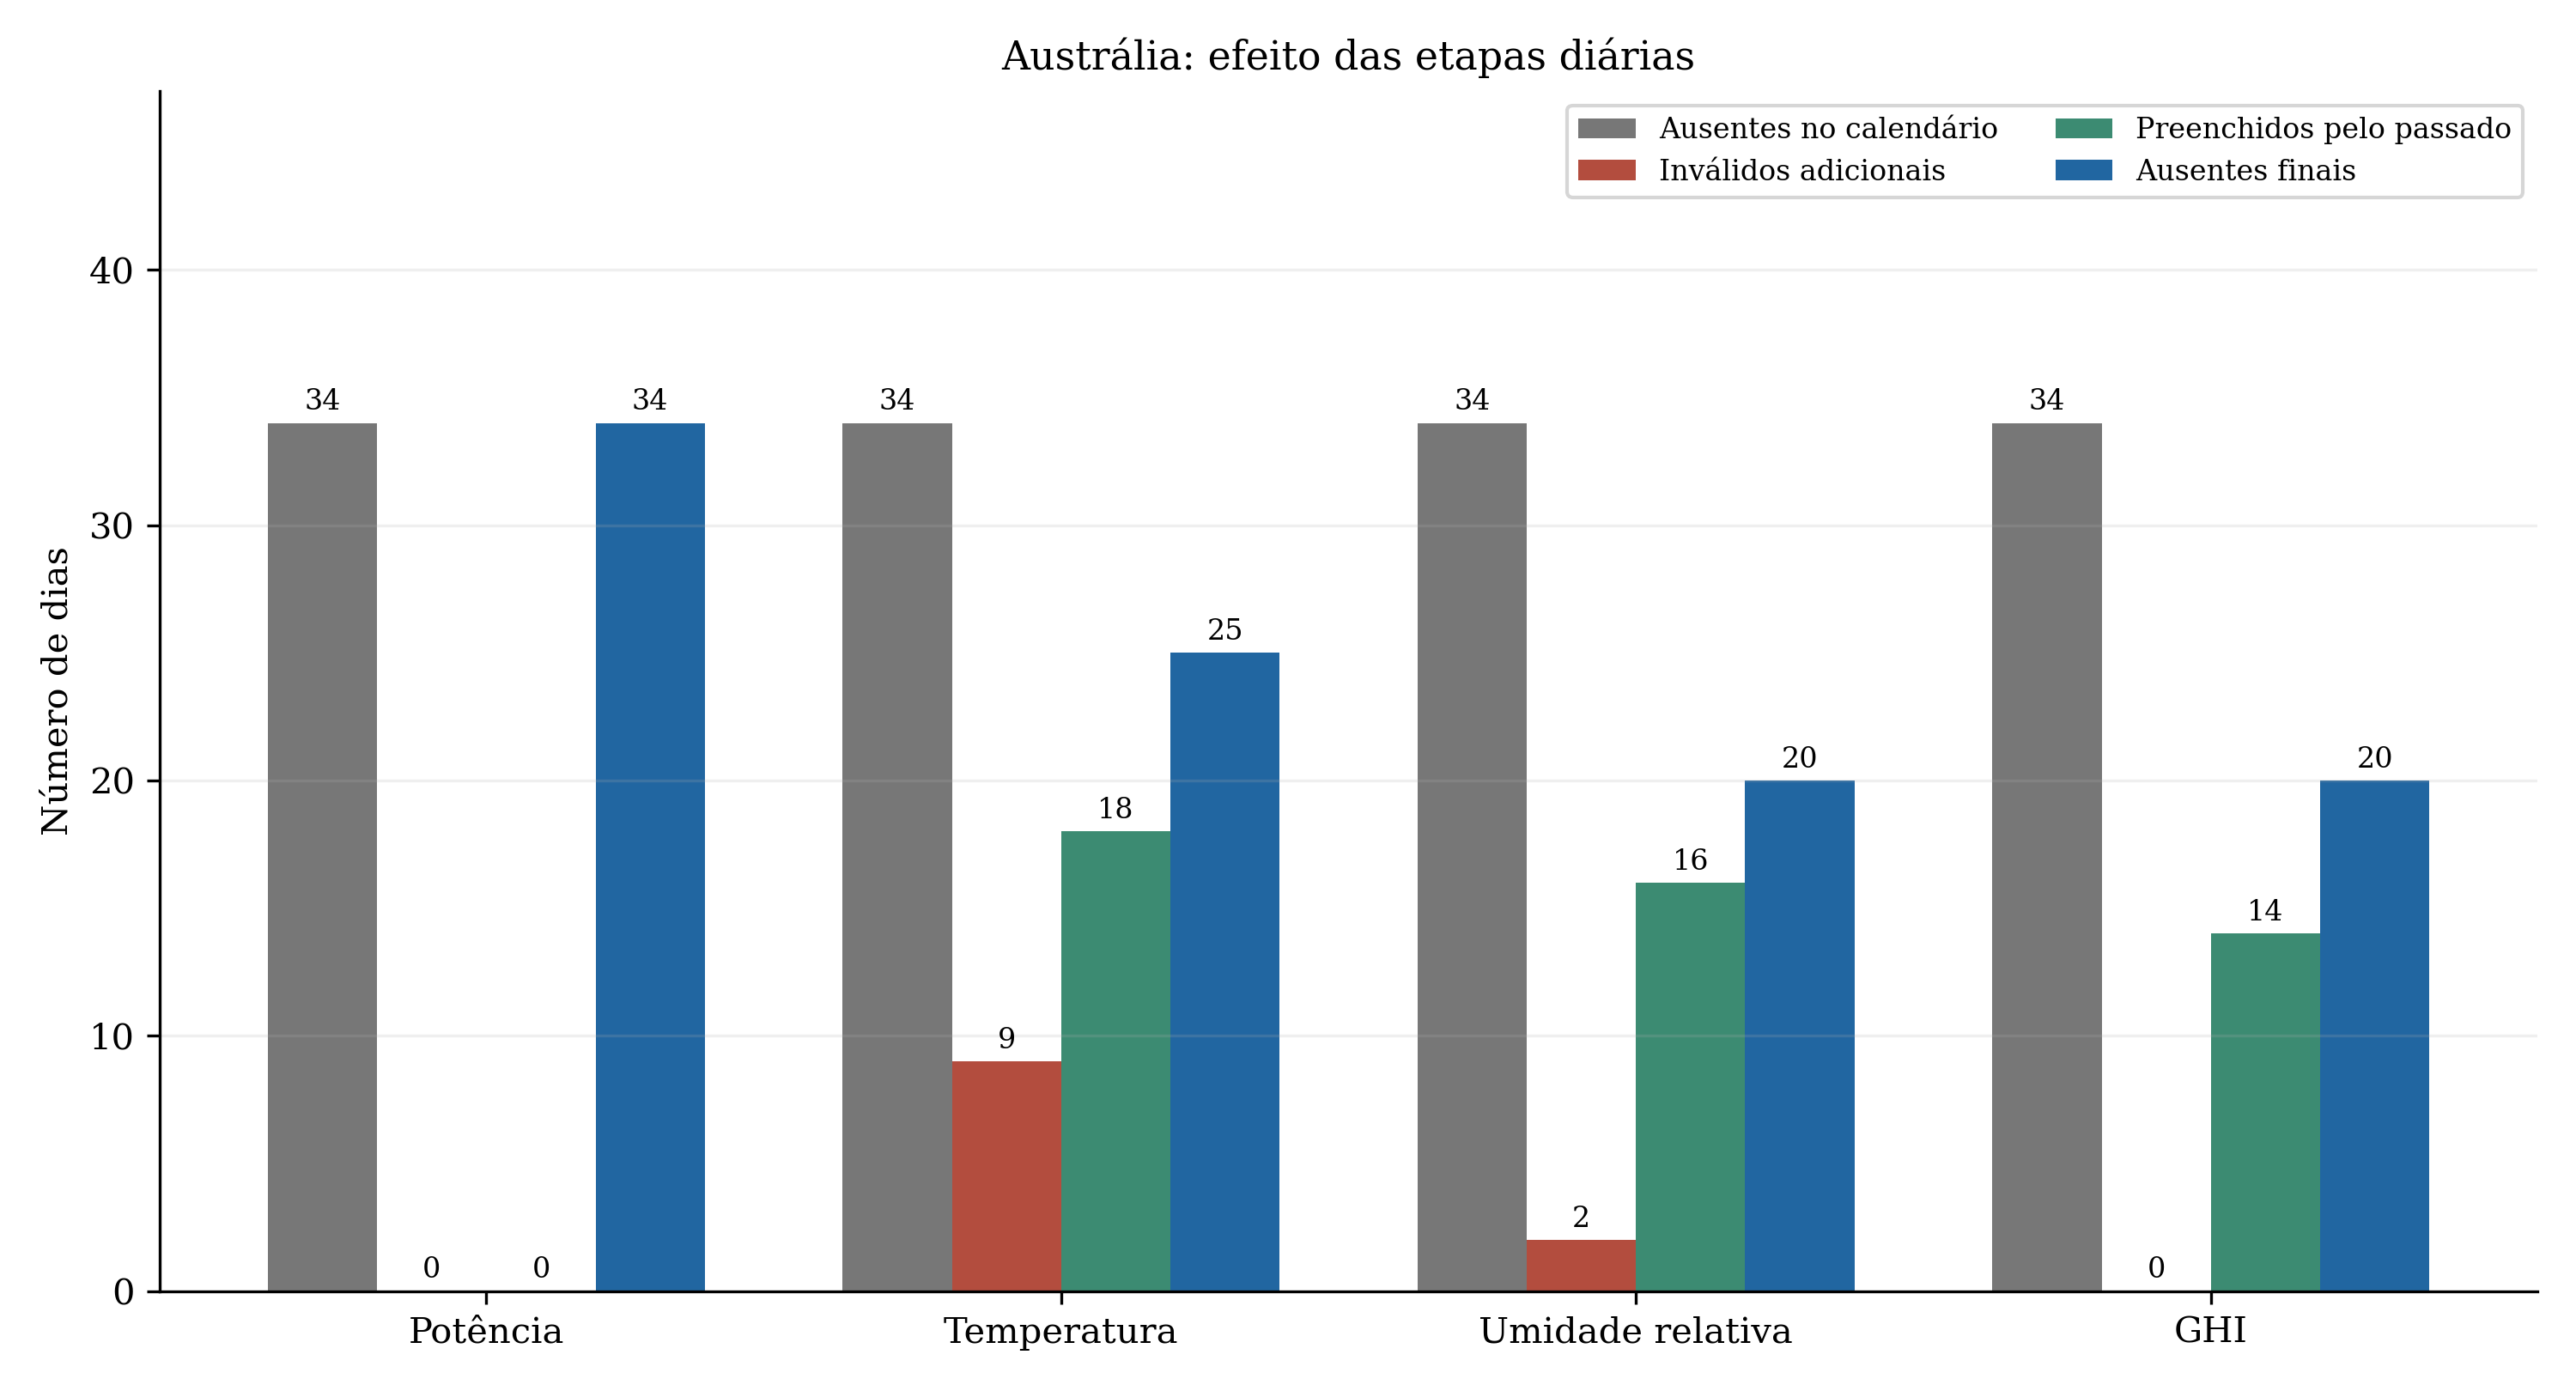

**Figura 3.3-01: Efeito das etapas de pré-processamento sobre a disponibilidade da base australiana.** Número de dias com valores ausentes, invalidados, preenchidos e ausentes após o tratamento, no calendário de 3812 dias até 31/12/2023. As ausências finais correspondem às ausências iniciais acrescidas das invalidações e descontadas as imputações. Os limites operacionais são aplicados às médias diárias. Apenas as variáveis meteorológicas recebem preenchimento; a potência permanece sem imputação.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

In [2]:
display(tabelas["australia_etapas"])
limites = pd.DataFrame(processamento["meta"]["limites_diarios"], index=["Mínimo diário", "Máximo diário"]).T
display(limites)
figura(1)

### Cobertura dos alvos australianos

O protocolo diário vigente calcula a média das amostras presentes, sem um filtro mínimo de cobertura intradiária. Assim, um dia pode ter um alvo numérico mesmo com leituras faltantes. A referência de 95% abaixo é **diagnóstica**; não foi aplicada retroativamente como exclusão.

Essa limitação deve acompanhar a descrição metodológica: completar a tabela diária e preencher covariáveis não assegura que a potência de cada dia represente 24 horas integralmente observadas.

,particao,alvos,menos_95pct,entre_95_e_100,completos,menor_contagem
0,treino,3392,10,43,3339,145
1,validacao,352,84,29,239,97


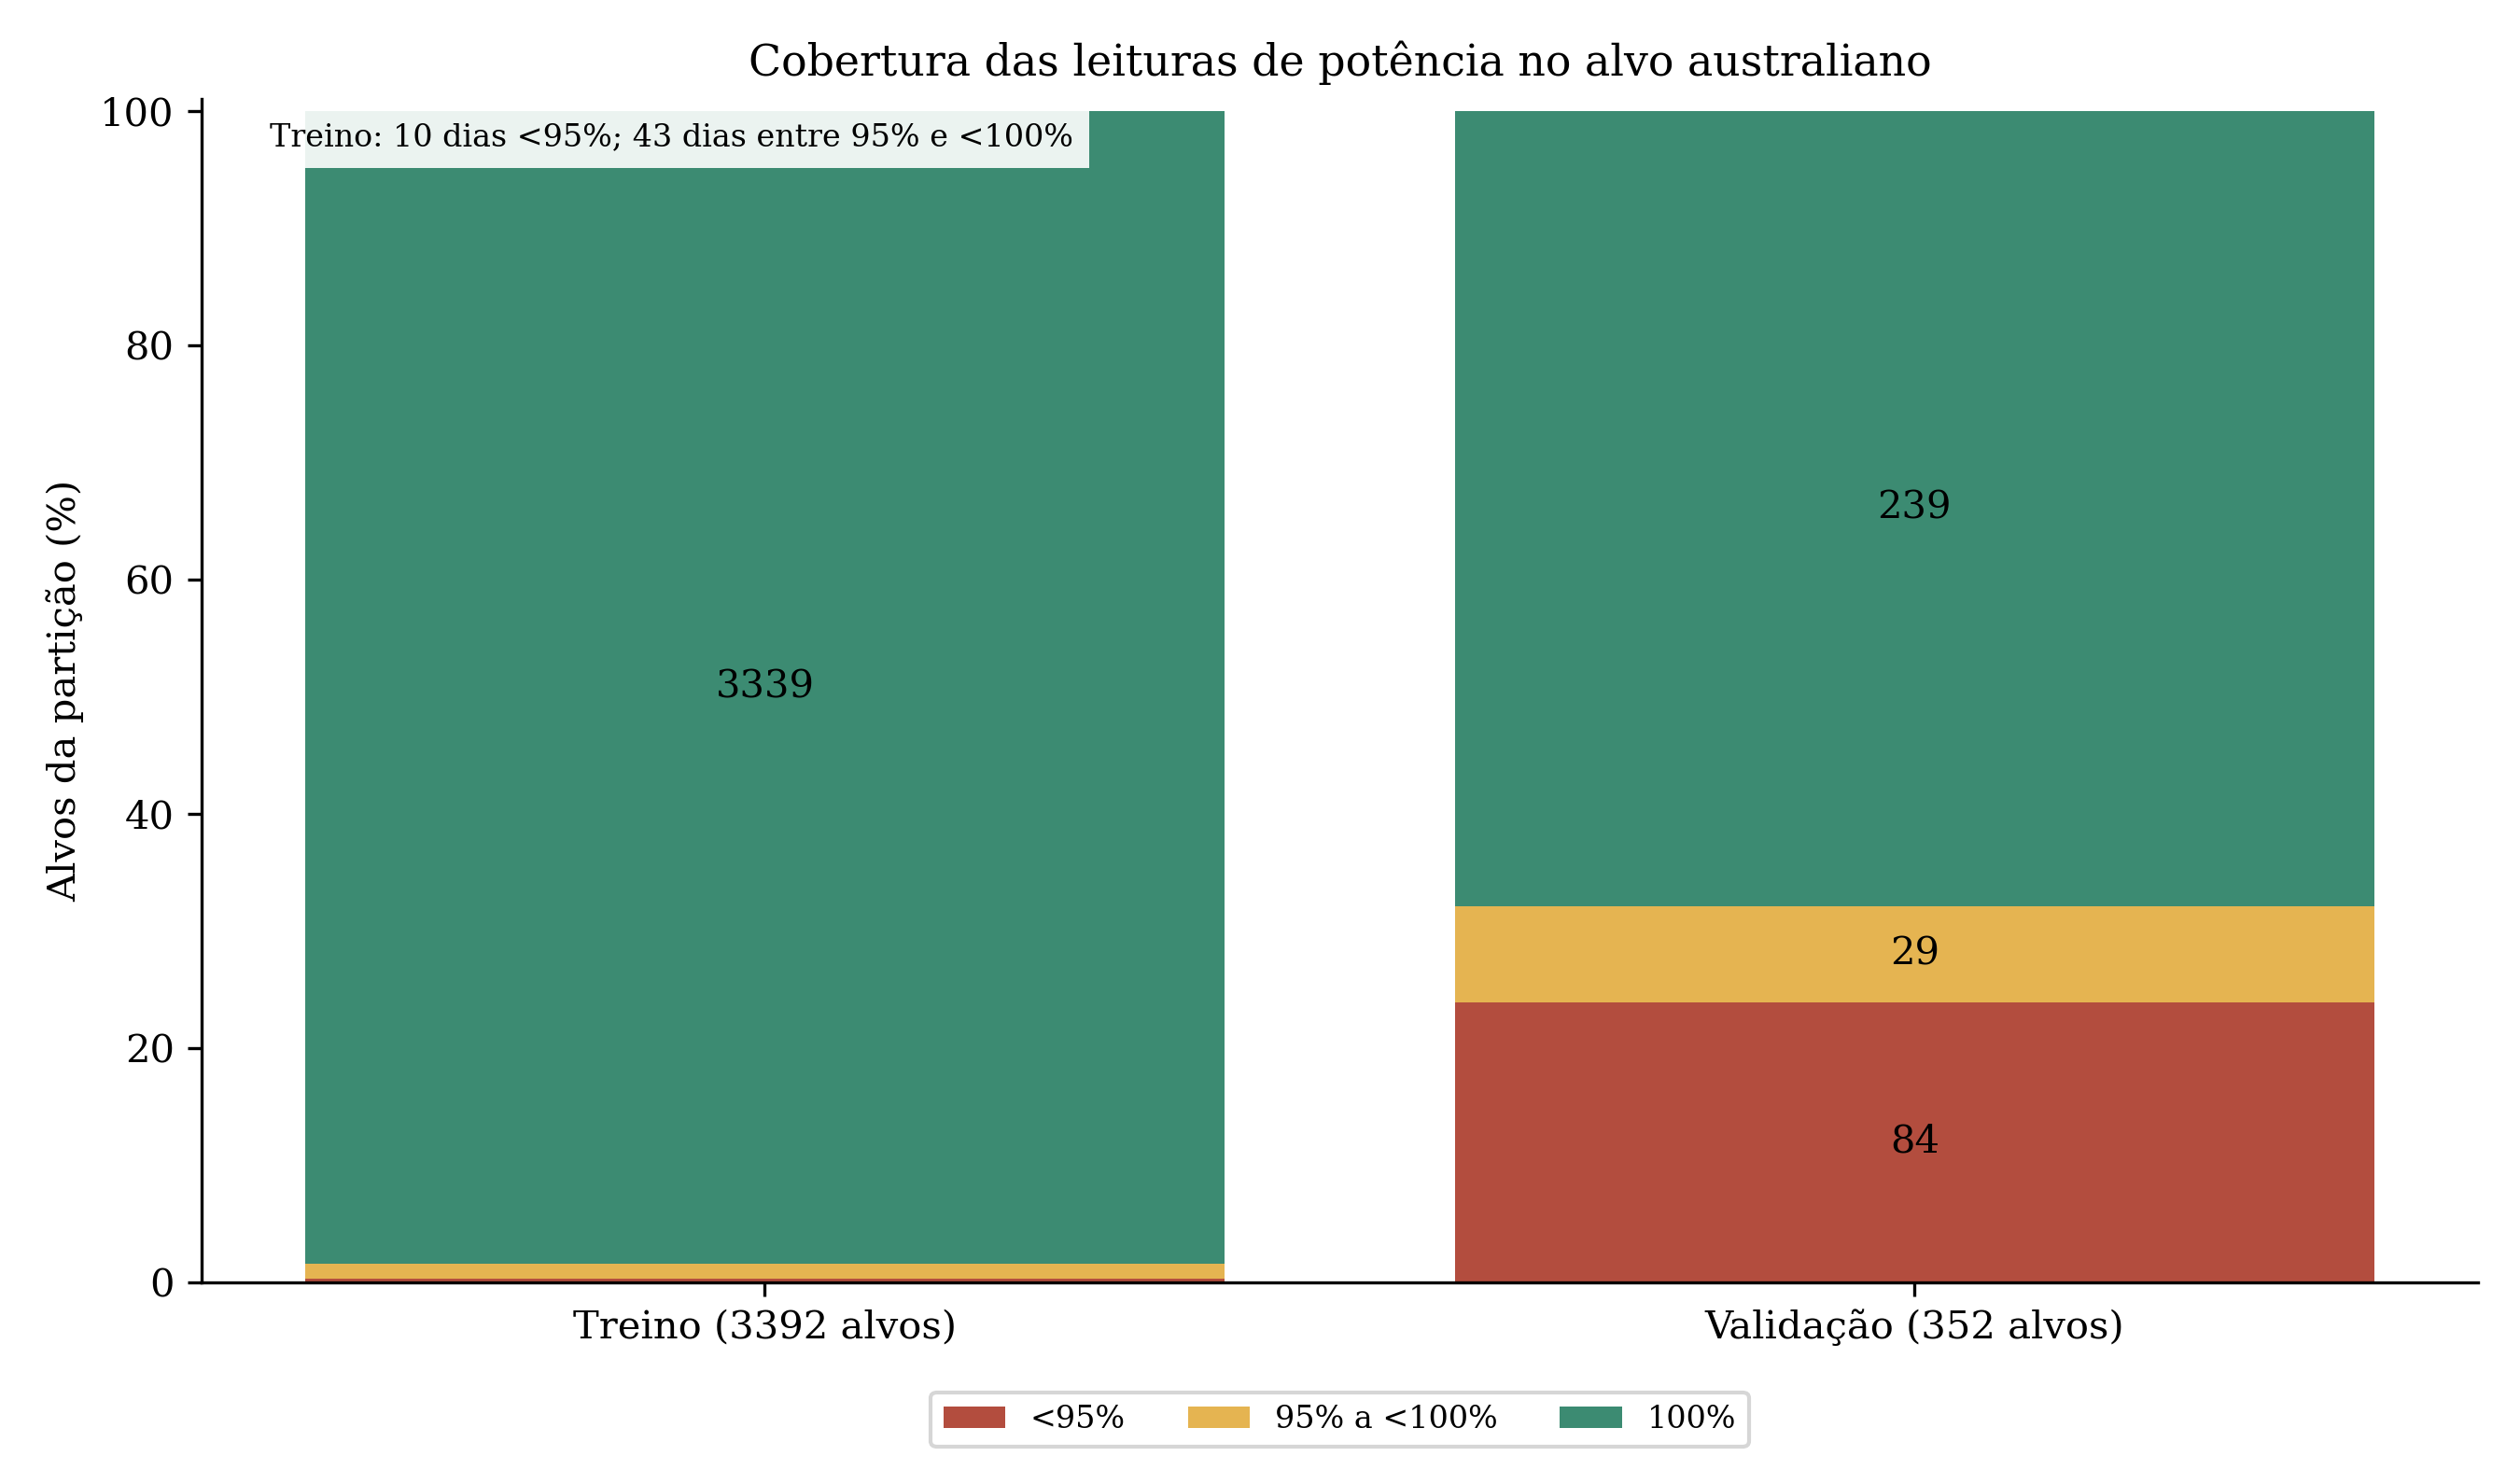

**Figura 3.3-03: Cobertura intradiária dos alvos australianos usados.** Distribuição dos alvos de treino e validação segundo a proporção de leituras de potência disponíveis em relação às 288 leituras esperadas por dia. Apresentam cobertura inferior a 95% dez dos 3392 alvos de treino e 84 dos 352 alvos de validação. O limiar de 95% é descritivo e não foi aplicado como critério de exclusão. A média das leituras disponíveis pode diferir da média integral de 24 horas.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

In [3]:
display(tabelas["australia_cobertura_alvos"])
figura(3)

## 3.3.2 Tratamento da base brasileira

O protocolo seleciona o código **07-07FX**, com oito inversores. Interpreta `datetime` em UTC, apresenta-o em `America/Sao_Paulo` e associa cada registro à posição anterior de cinco minutos (`floor`). Linhas sem timestamp ou equipamento são descartadas. Potência e contadores são convertidos em números, e valores negativos passam a ausentes. Registros do mesmo inversor e posição são consolidados pela mediana; depois se mantém o ano local de 2025.

**Contagens diferentes de duplicação:** a caracterização original usa a chave de timestamp original. O tratamento consolida também registros com timestamps distintos que caem na mesma posição de cinco minutos. Portanto, as 52.617 linhas excedentes consolidadas nesta etapa não equivalem às repetições de chave exata encontradas no CSV original.

Para cada inversor (i) e dia (d):

[
E^{dia}_{i,d}=max_{hgeq6} daily_power_yields_kwh,
]

[
E^{acum}_{i,d}=operatorname{mediana}_{hgeq19}(total_power_yields_kwh)-operatorname{mediana}_{h<4}(total_power_yields_kwh).
]

A aprovação exige as duas referências disponíveis e:

[
0leq E^{dia}_{i,d}leq1600;	ext{kWh},quad E^{acum}_{i,d}geq0,quad
|E^{dia}_{i,d}-E^{acum}_{i,d}|leqmax(8;	ext{kWh},0{,}03E^{dia}_{i,d}).
]

O dia da usina só é aprovado quando os **oito inversores** satisfazem as condições. Os horários e tolerâncias são regras deste projeto. Concordância dos contadores é consistência interna, não validação por medidor independente. Falta de uma borda necessária pode reprovar um dia mesmo havendo muitas leituras de potência.

,Indicador,Valor
0,usina,07-07FX
1,n_inversores,8
2,registros_5min_2025,680772
3,duplicatas_consolidadas,52617
4,dias_validos,284
5,dias_reprovados,81
6,imputacao_diaria,False


,motivo,dias_com_motivo
0,sem_registro_no_dia,27
1,sem_contador_diario_apos6,27
2,sem_borda_inicial,67
3,sem_borda_final,52
4,energia_fora_limite,0
5,acumulado_negativo,0
6,contadores_divergentes,0


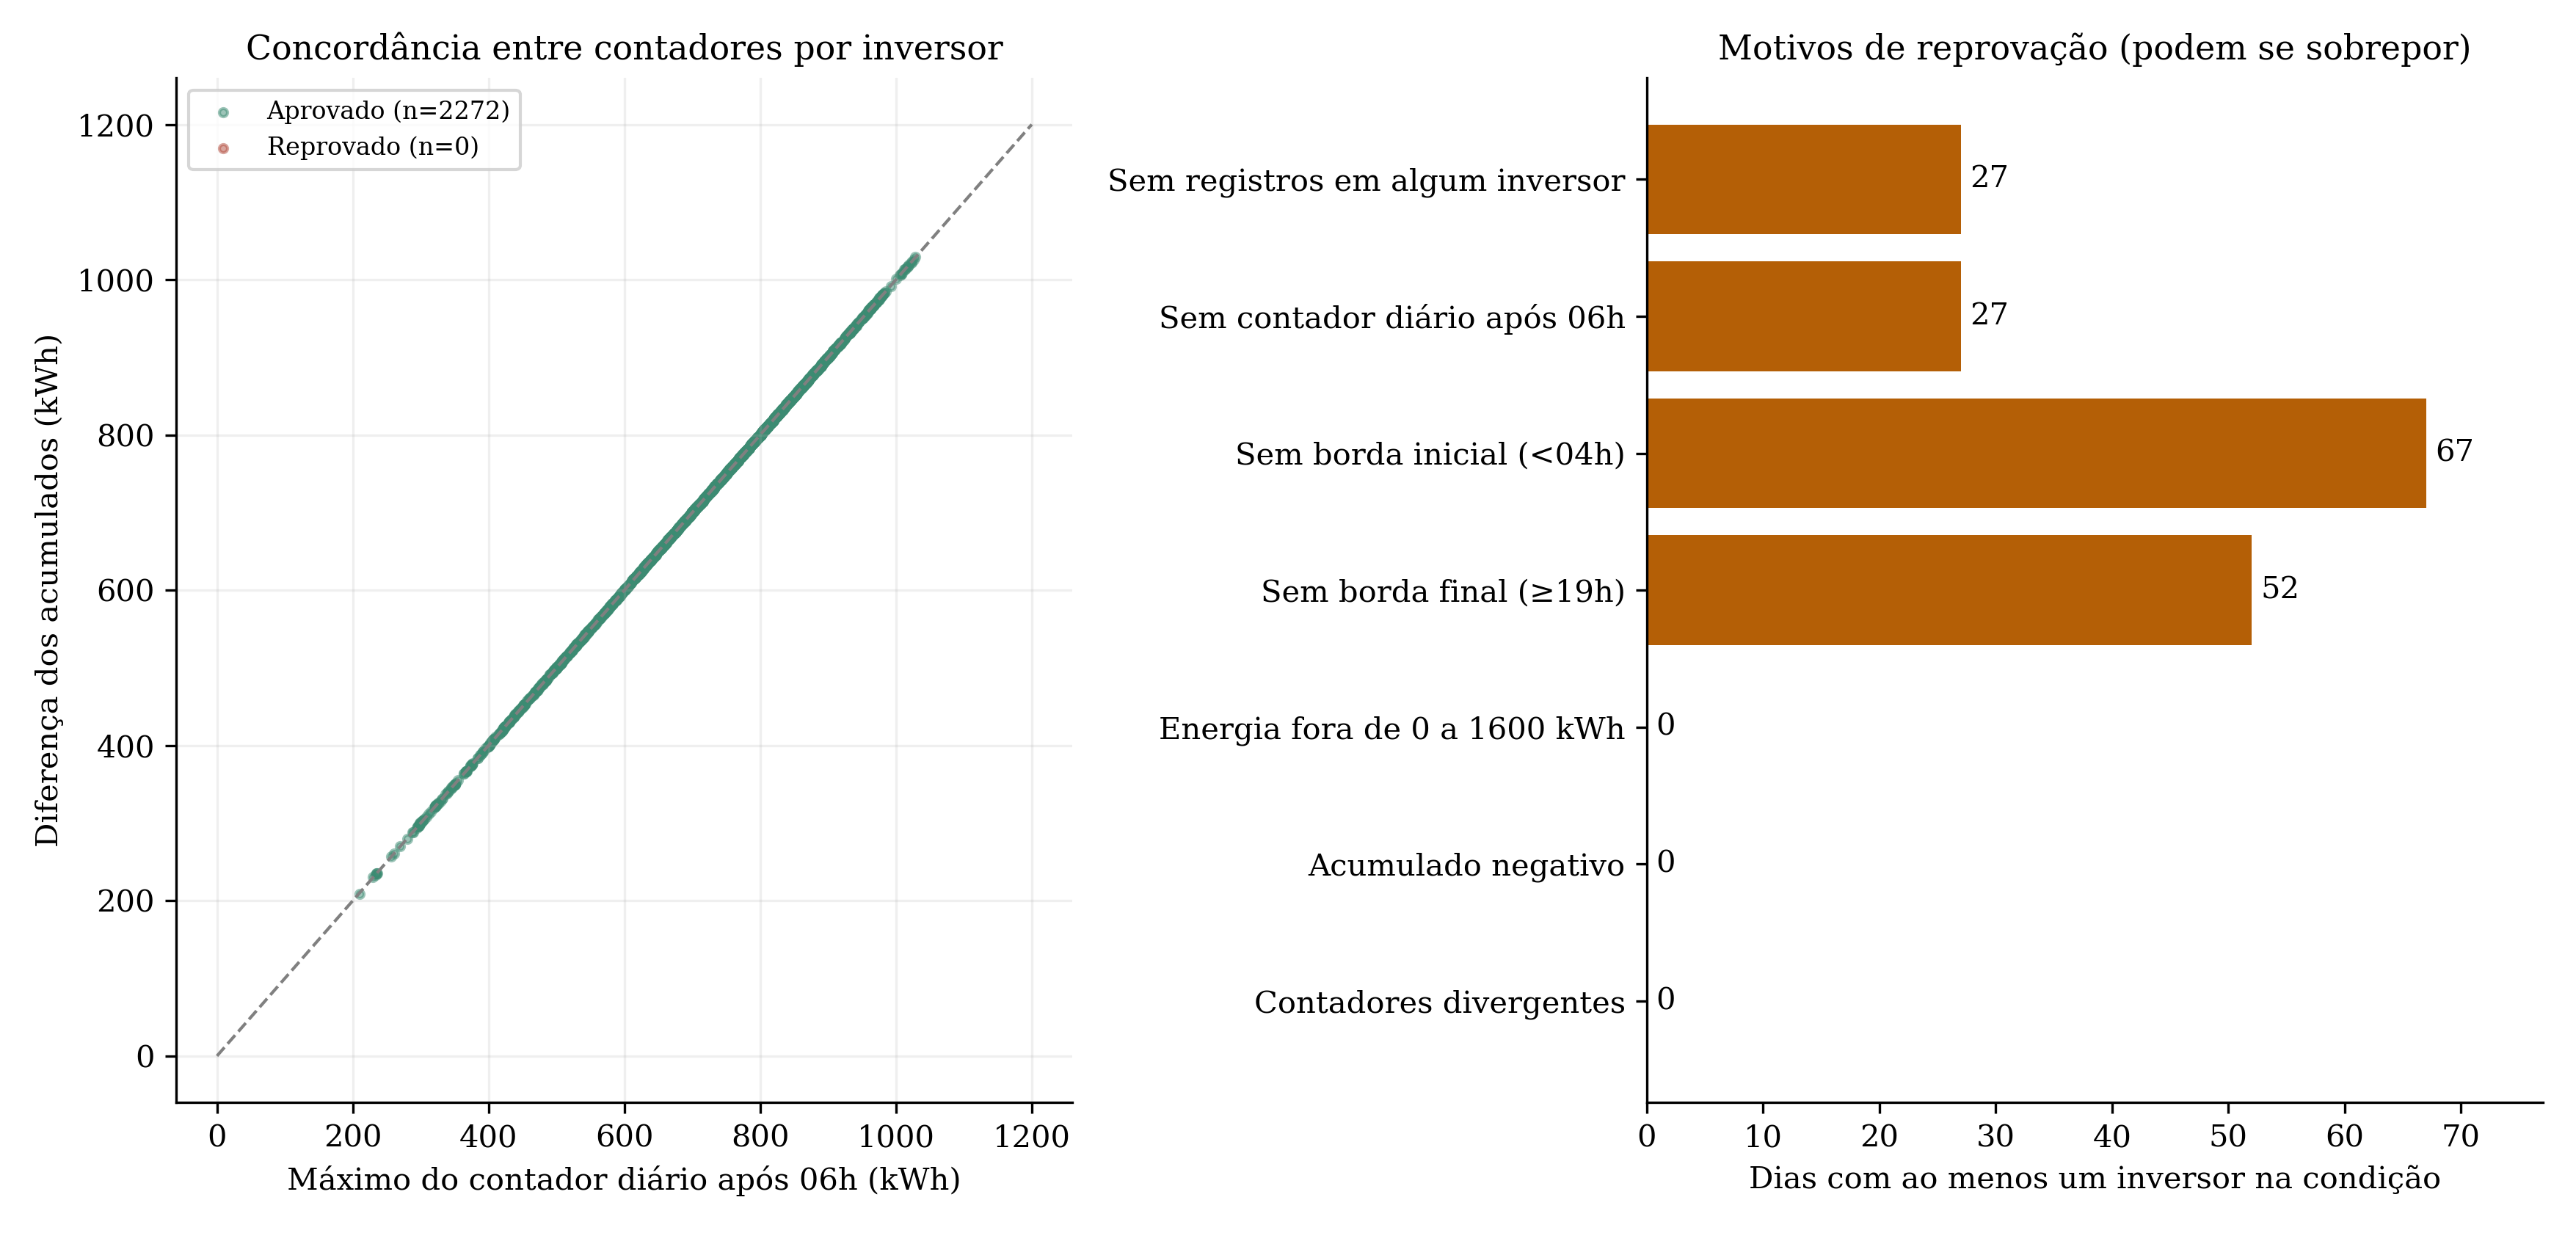

**Figura 3.3-04: Consistência dos contadores e reprovação de dias brasileiros.** Comparação entre a energia do contador diário e a diferença do contador acumulado por inversor, restrita aos pares com valores numéricos finitos. O painel direito apresenta a frequência dos critérios de reprovação diária, incluindo ausência das observações necessárias nas bordas do dia. A aprovação exige concordância dos oito inversores. Os critérios podem ocorrer simultaneamente; suas contagens não são aditivas. A concordância representa consistência interna dos contadores.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

In [4]:
meta_br = processamento["meta"]["brasil"]
campos = ["usina", "n_inversores", "registros_5min_2025", "duplicatas_consolidadas", "dias_validos", "dias_reprovados", "imputacao_diaria"]
display(pd.DataFrame({"Indicador": campos, "Valor": [meta_br[c] for c in campos]}))
display(tabelas["brasil_motivos"])
figura(4)

### Meteorologia brasileira usada na aplicação

Nesta versão, temperatura, umidade e GHI vêm integralmente do **ERA5 via Open-Meteo**, com uma fonte homogênea. A estação local caracteriza a coleta em 3.2, mas não é combinada com a reanálise nas três covariáveis do modelo.

São usadas médias de 24 valores horários por dia local. A radiação horária é associada ao intervalo anterior, deslocando o índice em uma hora para trás antes da agregação. Um dia sem as 24 horas necessárias permanece ausente. O GHI diário continua em W/m², incluindo a noite, e não é energia solar diária em kWh/m².

Localização solicitada: −16,55°, −48,85°, 927 m; célula retornada próxima de −16,50°, −48,75°. O cache resulta em 364 dias meteorológicos completos em 2025; 01/01 permanece ausente.

A reanálise é retrospectiva e não equivale a uma previsão meteorológica operacional. O modelo usa somente os dias passados; a latência de publicação da fonte não foi simulada. Esses limites precisam constar da metodologia.

,variavel,dias_completos,ausentes,dias_calendario
0,Weather_Temperature_Celsius,364,1,365
1,Weather_Relative_Humidity,364,1,365
2,Global_Horizontal_Radiation,364,1,365


,Dias
Estado,
Aprovado,284
Reprovado com registros,62
Sem registros,19


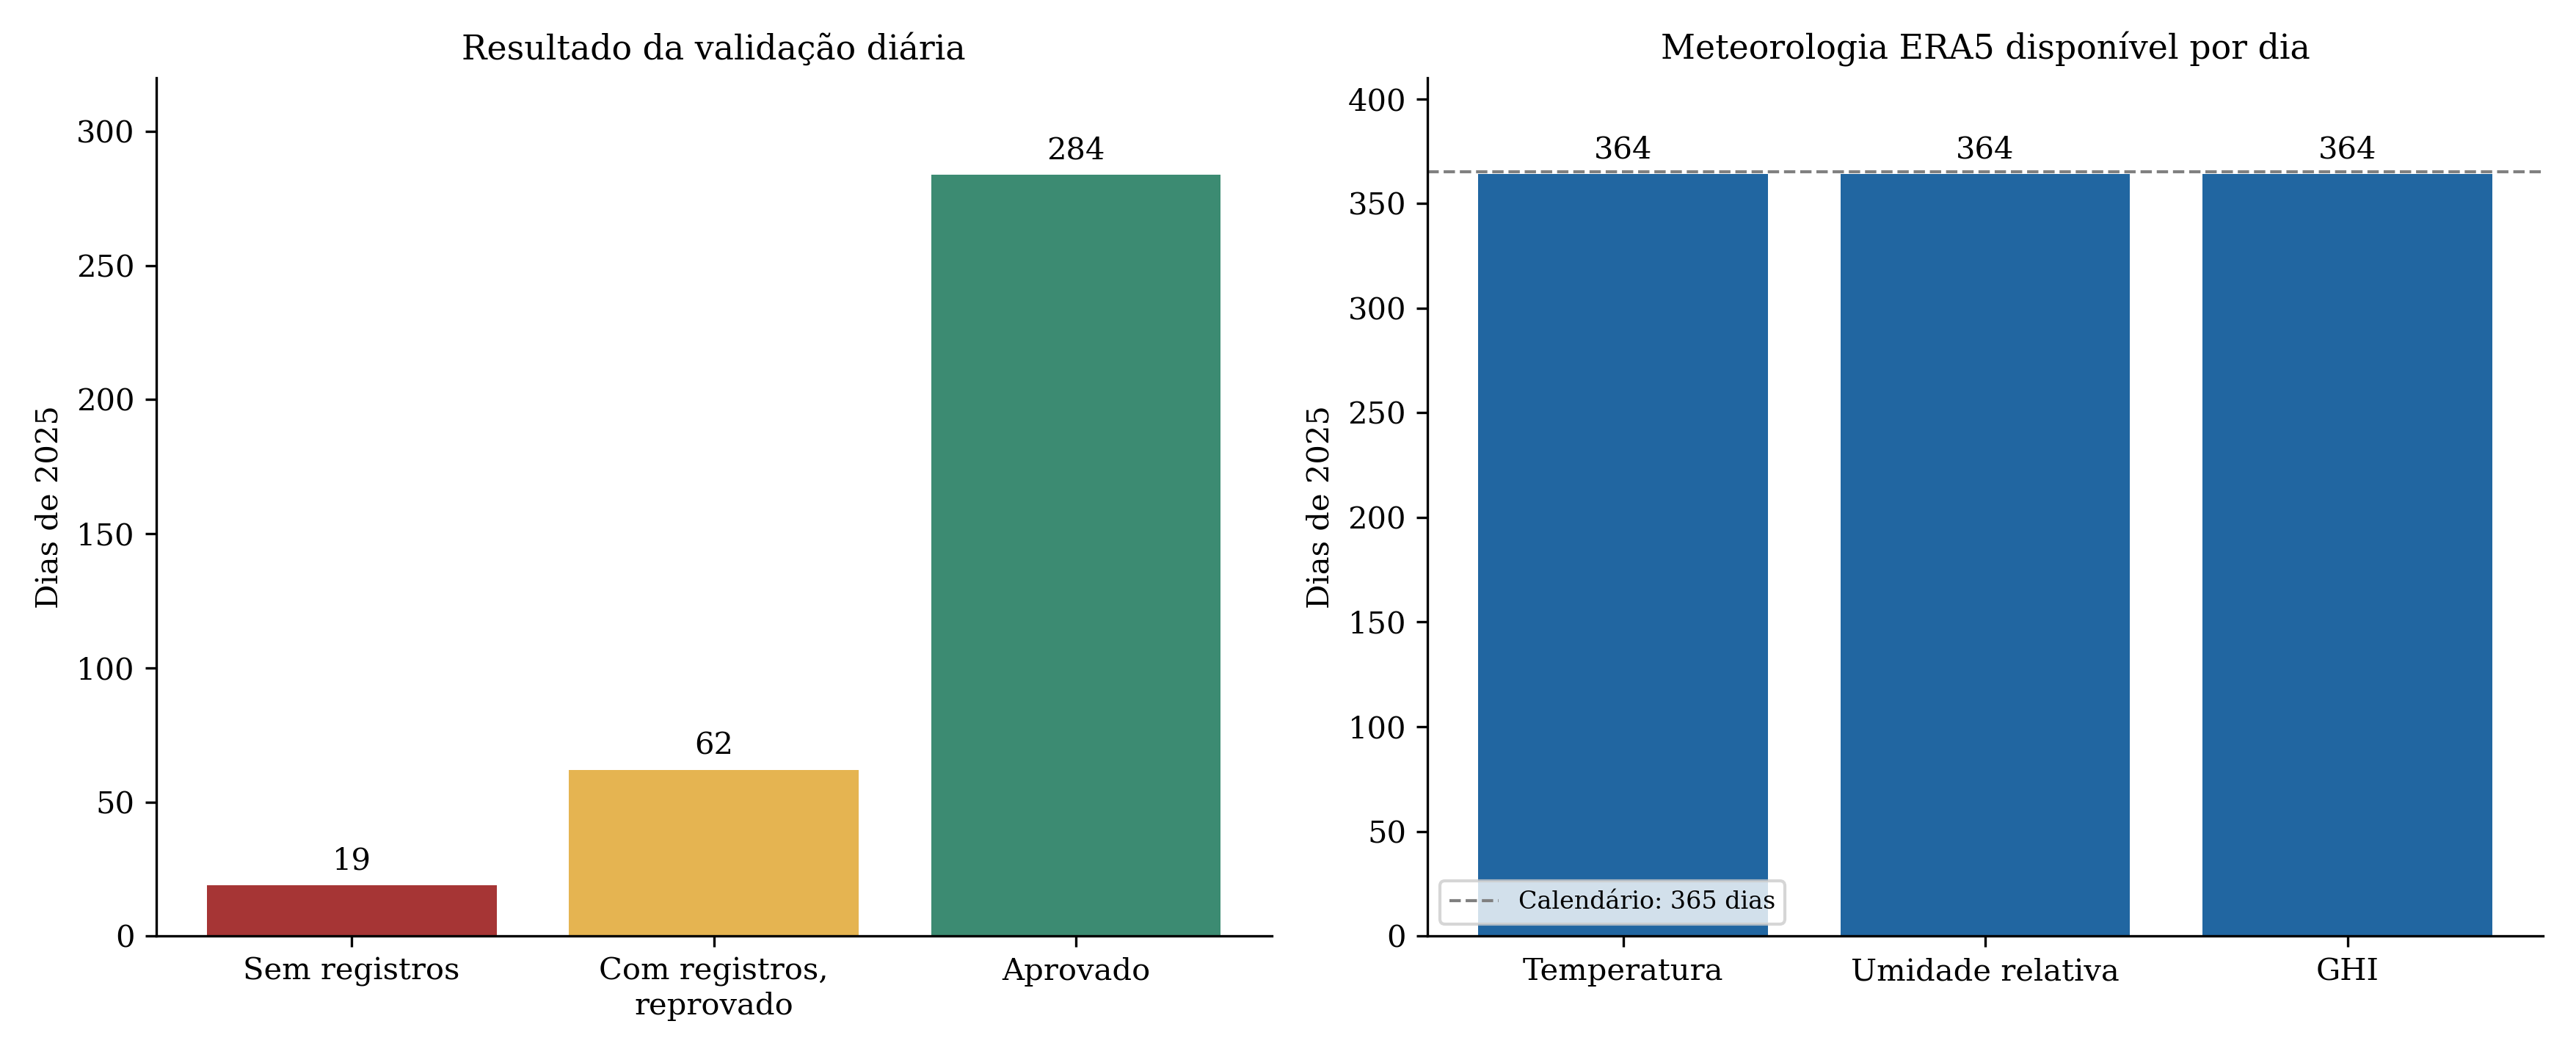

**Figura 3.3-05: Disponibilidade após reconstrução brasileira e meteorologia pública.** Classificação dos 365 dias de 2025 quanto à reconstrução do alvo brasileiro: 19 dias sem registros, 62 dias com registros reprovados e 284 dias aprovados. As três variáveis meteorológicas do ERA5 apresentam 364 dias completos, permanecendo ausentes em 01/01/2025. Os alvos diários não recebem imputação; as covariáveis meteorológicas provêm integralmente da reanálise.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

In [5]:
display(tabelas["meteorologia_era5"])
display(tabelas["brasil_estados"].estado.value_counts().rename_axis("Estado").to_frame("Dias"))
figura(5)

## 3.3.3 Construção da potência média diária

**Austrália:** média aritmética das leituras disponíveis de potência no dia, incluindo as noturnas presentes:

[
ar P_{AU,d}=rac{1}{n_d}sum_{kinmathcal O_d}P_{d,k}.
]

(n_d) é o número de leituras disponíveis. Se faltam horários, esse valor pode diferir da média integral das 24 horas.

**Brasil:** soma dos contadores diários dos oito inversores aprovados e conversão de energia em potência média equivalente de 24 horas:

[
E_{BR,d}=sum_{i=1}^{8}E^{dia}_{i,d},qquad
ar P_{BR,d}=rac{E_{BR,d}}{24;mathrm h}.
]

Energia em kWh dividida por 24 horas resulta em kW. O método pode recuperar a referência diária apesar de faltarem leituras intradiárias de potência, desde que existam e concordem os contadores exigidos. Isso não significa interpolar cada leitura perdida.

Os países usam definições diferentes de construção do alvo, que precisam ser declaradas. Não se soma apenas uma parte dos oito inversores para representar a usina inteira nos dias reprovados.

,n_consistentes,energia_kwh,Active_Power
timestamp,,,
2025-01-30,8.00000,5291.00000,220.45833
2025-01-31,8.00000,3742.30000,155.92917
2025-02-01,8.00000,5052.00000,210.50000
2025-02-02,8.00000,5834.00000,243.08333
2025-02-03,8.00000,4073.20000,169.71667
2025-02-04,8.00000,6247.70000,260.32083
2025-02-05,8.00000,5752.10000,239.67083
2025-02-06,8.00000,7622.70000,317.61250
2025-02-07,8.00000,5993.90000,249.74583


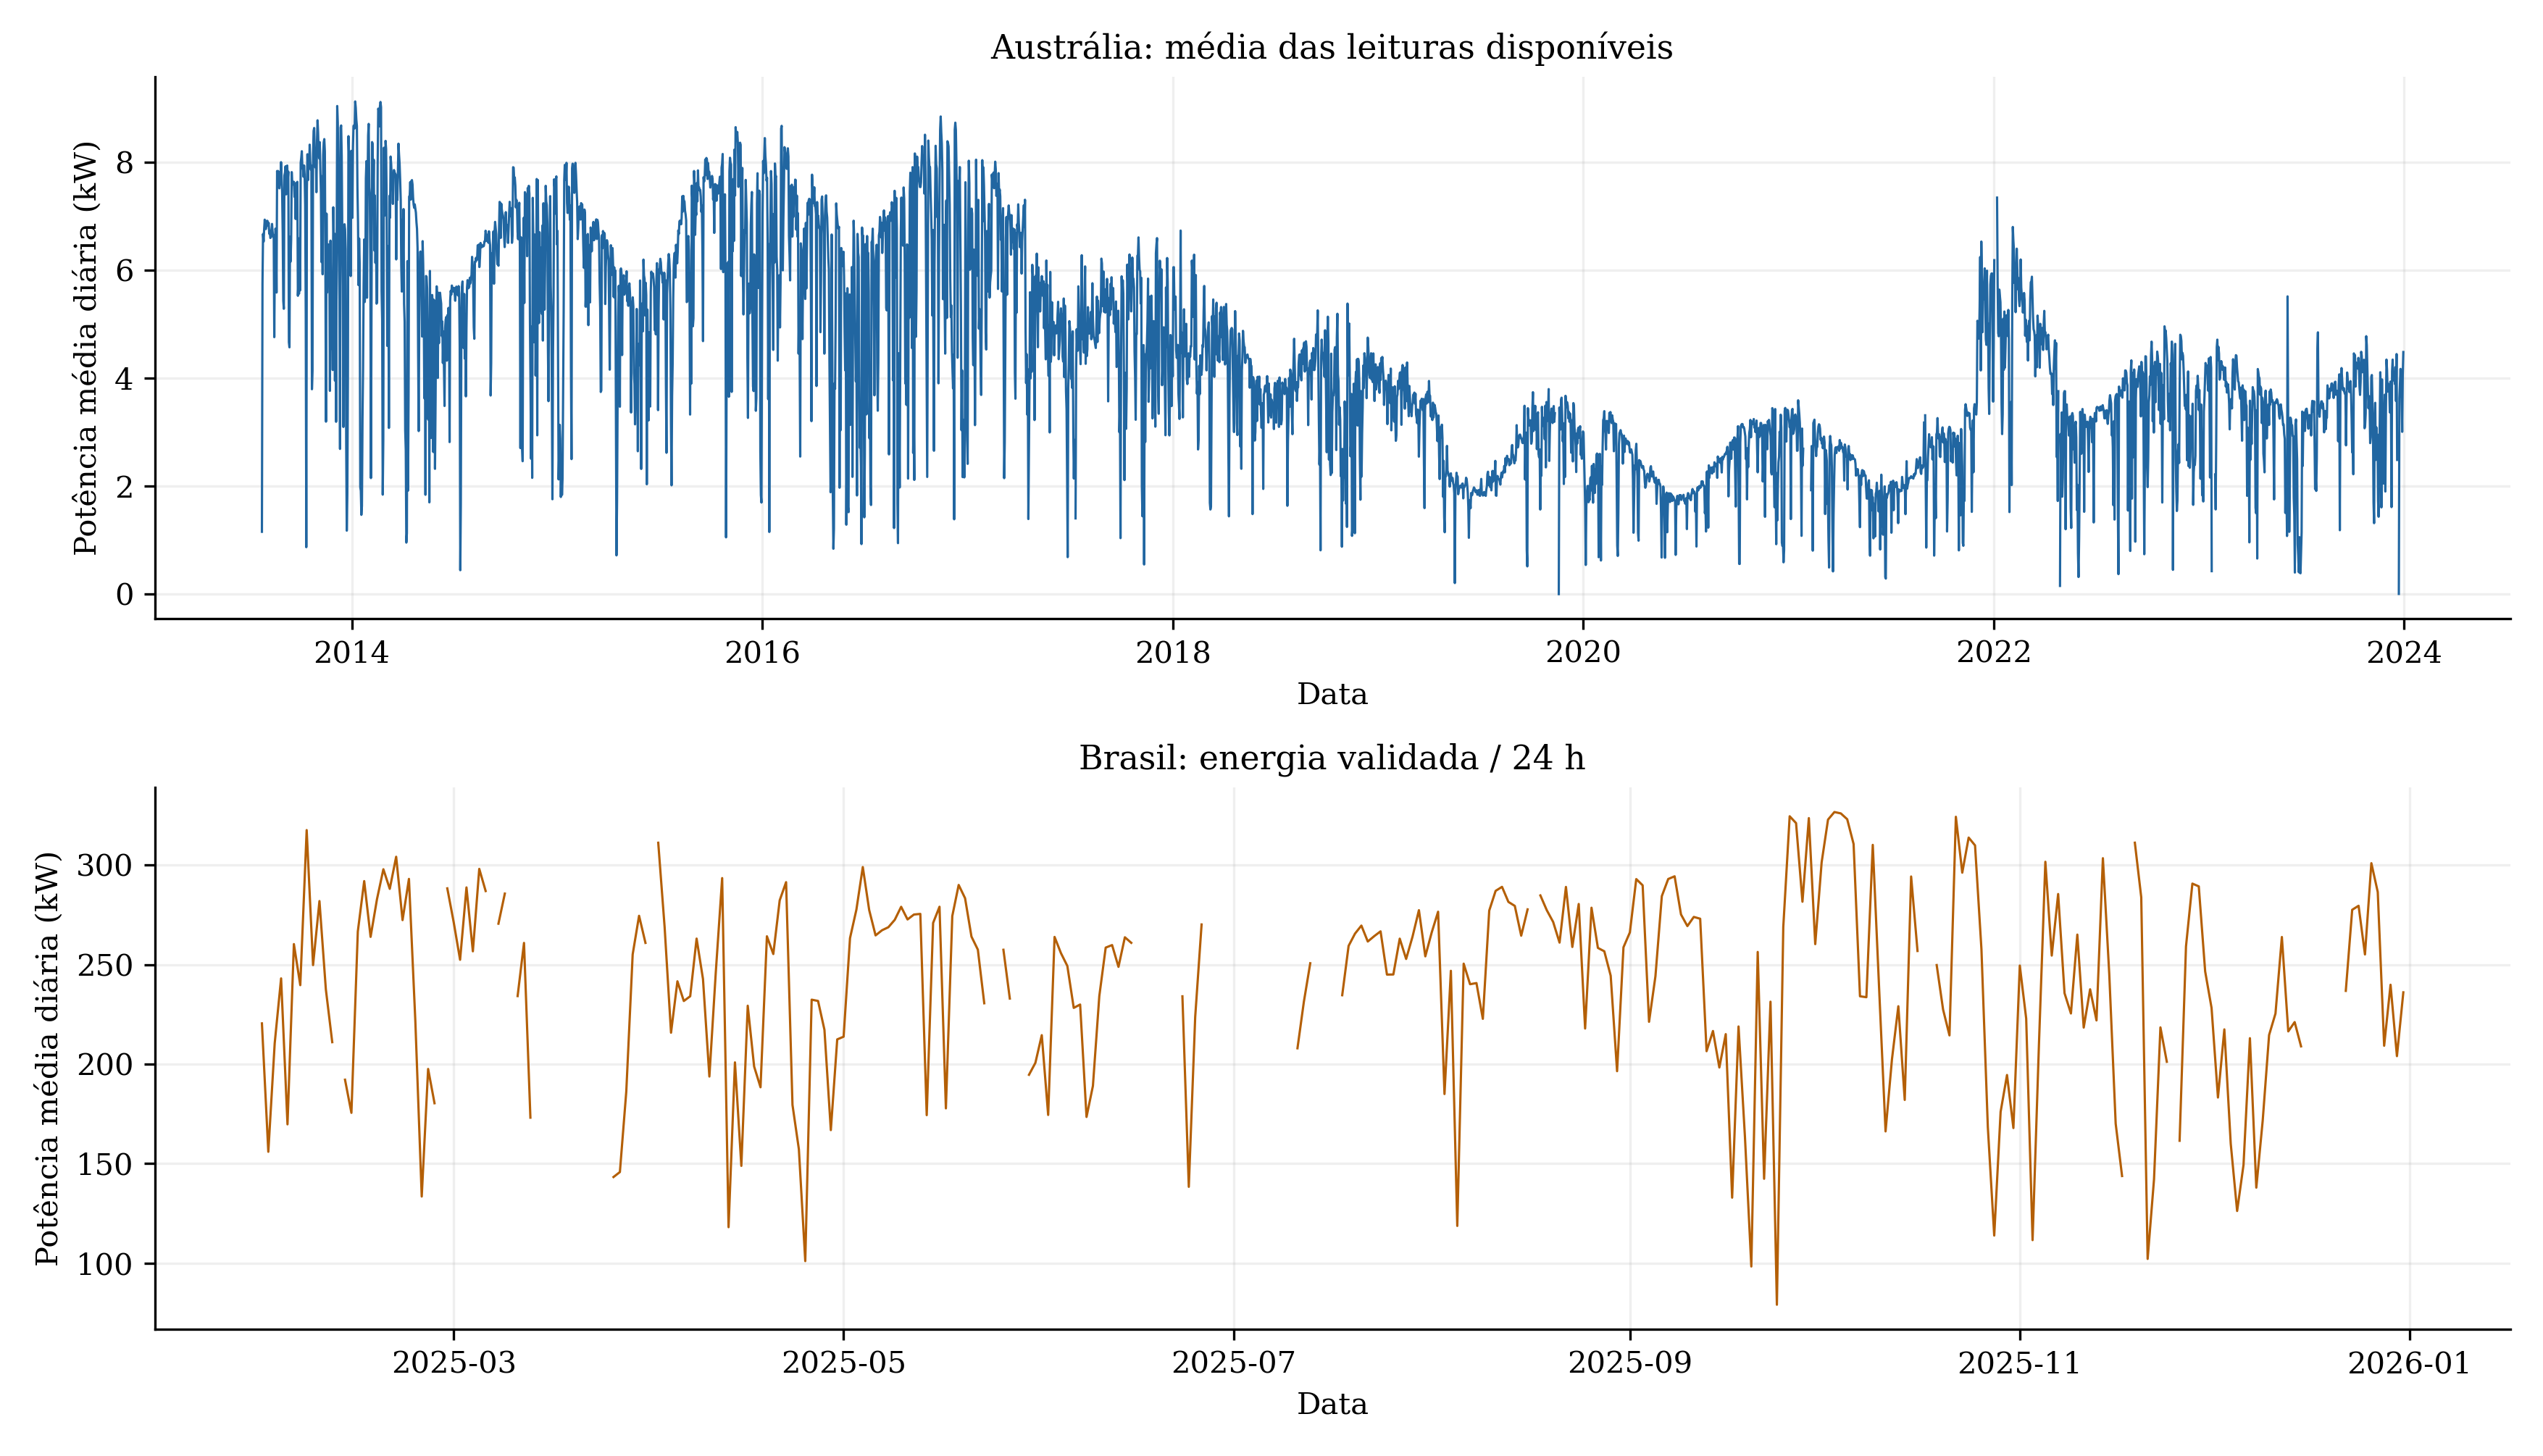

**Figura 3.3-06: Séries de potência média diária após o pré-processamento.** Potência média diária australiana calculada pela média aritmética das leituras disponíveis e potência média equivalente brasileira calculada pela soma da energia diária dos oito inversores aprovados dividida por 24 horas. As lacunas são preservadas no calendário e interrompem as séries. As bases apresentam períodos de observação e procedimentos de construção do alvo distintos.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

In [6]:
au, br = processamento["au"], processamento["br"]
np.testing.assert_allclose(br.Active_Power, br.energia_kwh/24, atol=1e-10, equal_nan=True)
display(br.loc[br.valido, ["n_consistentes", "energia_kwh", "Active_Power"]].head(10))
figura(6)

## 3.3.4 Tratamento dos valores ausentes

**Austrália:** apenas meteorologia recebe `ffill(limit=2)`, usando o passado. Não se aplicam interpolação linear bidirecional, KNN ou preenchimento do alvo nesta versão. Os pontos preenchidos aparecem nos exemplos abaixo; eles são estimativas e não novas medições.

**Brasil:** dias reprovados continuam ausentes. A recuperação de energia por contadores é condicionada à validação e não é uma imputação de dias inteiros. A meteorologia é substituída integralmente pela fonte pública escolhida; não se usam misturas locais em lacunas individuais. O dia meteorológico incompleto de 01/01 não é extrapolado.

**Janelas:** para prever o dia (d), usam-se (d-3,d-2,d-1). Exigem-se potência nos quatro dias e covariáveis nos três dias passados. O calendário não é comprimido e nenhuma janela salta uma interrupção. A meteorologia do próprio alvo não é exigida nem fornecida como informação futura. Janelas sobrepostas não constituem observações estatisticamente independentes.

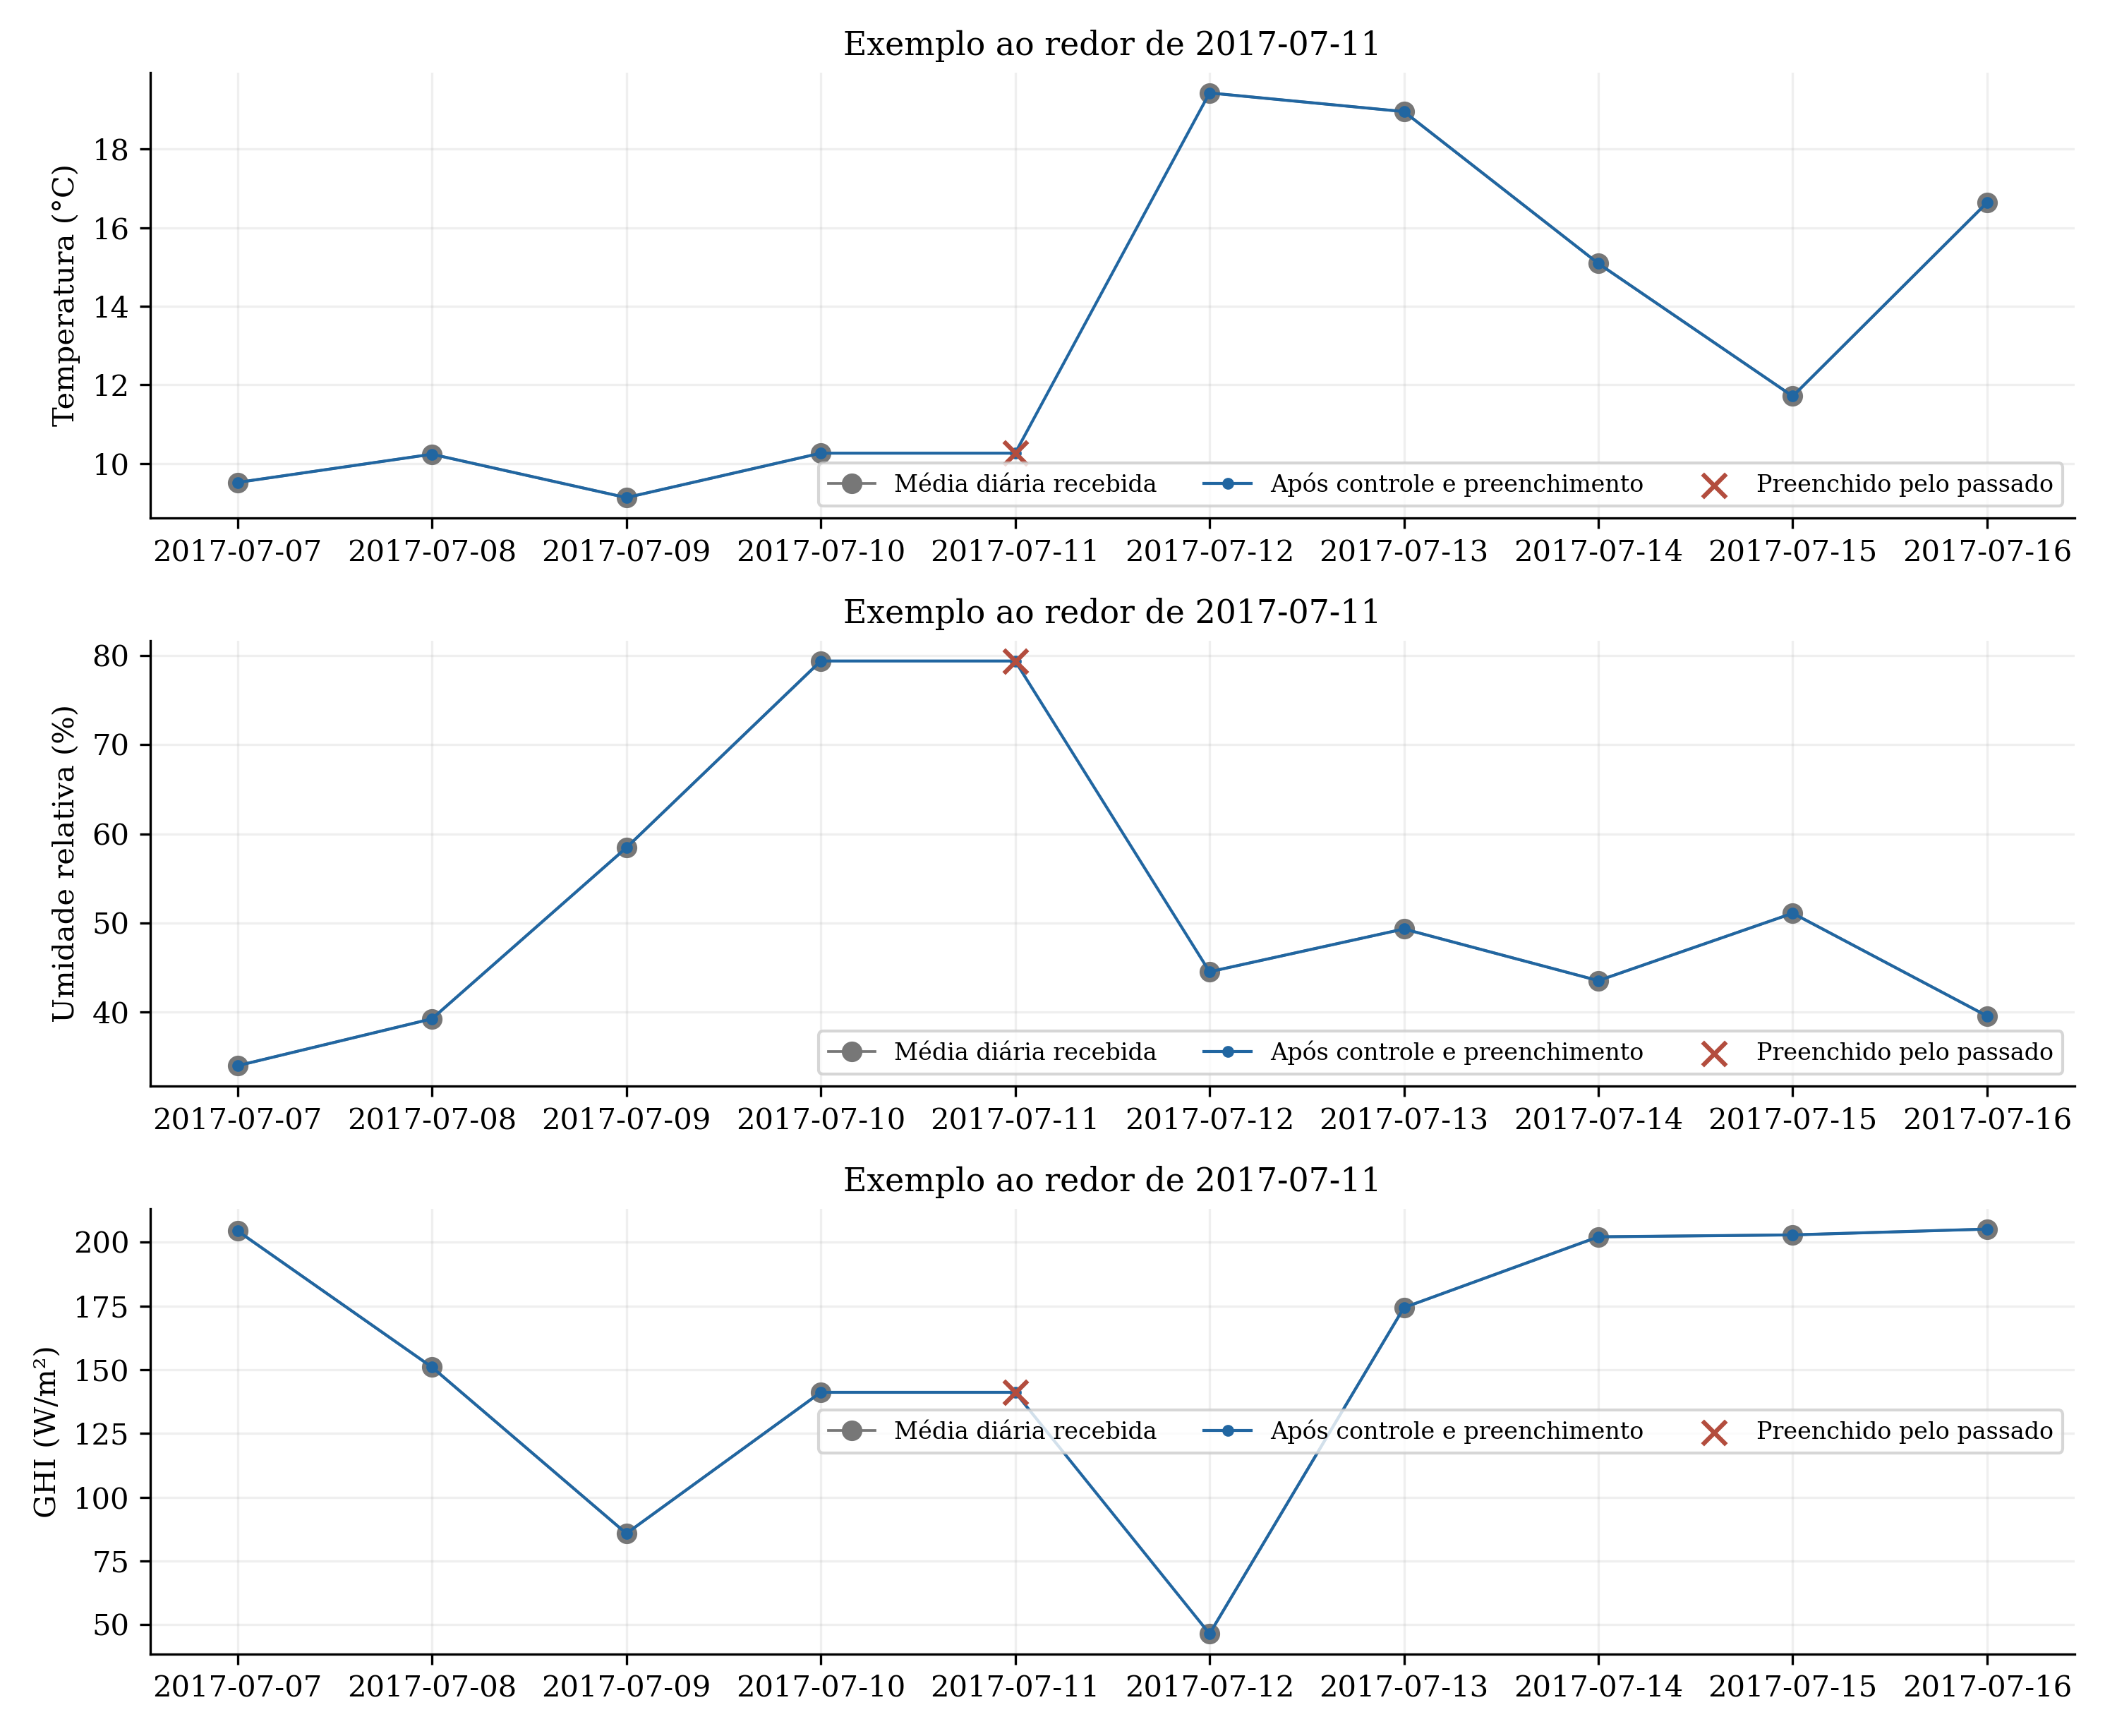

**Figura 3.3-02: Exemplos do preenchimento causal meteorológico.** Séries diárias de temperatura, umidade relativa e GHI no entorno da primeira ocorrência de imputação de cada variável. O preenchimento propaga a última observação válida por até dois dias consecutivos, utilizando exclusivamente informações passadas. Os marcadores identificam os valores imputados. Os exemplos ilustram o procedimento e não constituem uma avaliação de sua precisão.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

,Austrália,Brasil
Variável,,
Active_Power,34,81
Weather_Temperature_Celsius,25,1
Weather_Relative_Humidity,20,1
Global_Horizontal_Radiation,20,1


,inicio,fim,posicoes,minutos,dias,dominio
0,2017-07-11,2017-07-11,1,1440.00000,1,Austrália
1,2019-11-13,2019-11-18,6,8640.00000,6,Austrália
2,2021-01-28,2021-02-09,13,18720.00000,13,Austrália
3,2021-08-31,2021-08-31,1,1440.00000,1,Austrália
4,2022-01-03,2022-01-06,4,5760.00000,4,Austrália
5,2022-04-27,2022-04-28,2,2880.00000,2,Austrália
6,2023-01-25,2023-01-29,5,7200.00000,5,Austrália
7,2023-12-21,2023-12-22,2,2880.00000,2,Austrália
8,2025-01-01,2025-01-29,29,41760.00000,29,Brasil
9,2025-02-11,2025-02-11,1,1440.00000,1,Brasil


In [7]:
figura(2)
faltantes = pd.concat([
    au[["Active_Power", "Weather_Temperature_Celsius", "Weather_Relative_Humidity", "Global_Horizontal_Radiation"]].isna().sum().rename("Austrália"),
    br[["Active_Power", "Weather_Temperature_Celsius", "Weather_Relative_Humidity", "Global_Horizontal_Radiation"]].isna().sum().rename("Brasil")
], axis=1)
display(faltantes.rename_axis("Variável"))
faltantes.to_csv(processamento["tabelas_dir"] / "faltantes_finais_por_variavel.csv")
display(tabelas["lacunas_alvo_diario"])

,dominio,etapa,n,pct
0,Austrália,Calendário,3812,100.00000
1,Austrália,Alvo disponível,3778,99.10808
2,Austrália,Janela de 3 dias + alvo,3744,98.21616
3,Brasil,Calendário,365,100.00000
4,Brasil,Alvo disponível,284,77.80822
5,Brasil,Janela de 3 dias + alvo,230,63.01370


,dominio,particao,n,inicio,fim
0,Austrália,treino,3392,2013-07-28,2022-12-31
1,Austrália,validacao,352,2023-01-01,2023-12-31
2,Brasil,treino,160,2025-02-02,2025-09-30
3,Brasil,validacao,26,2025-10-01,2025-10-31
4,Brasil,teste,44,2025-11-01,2025-12-31


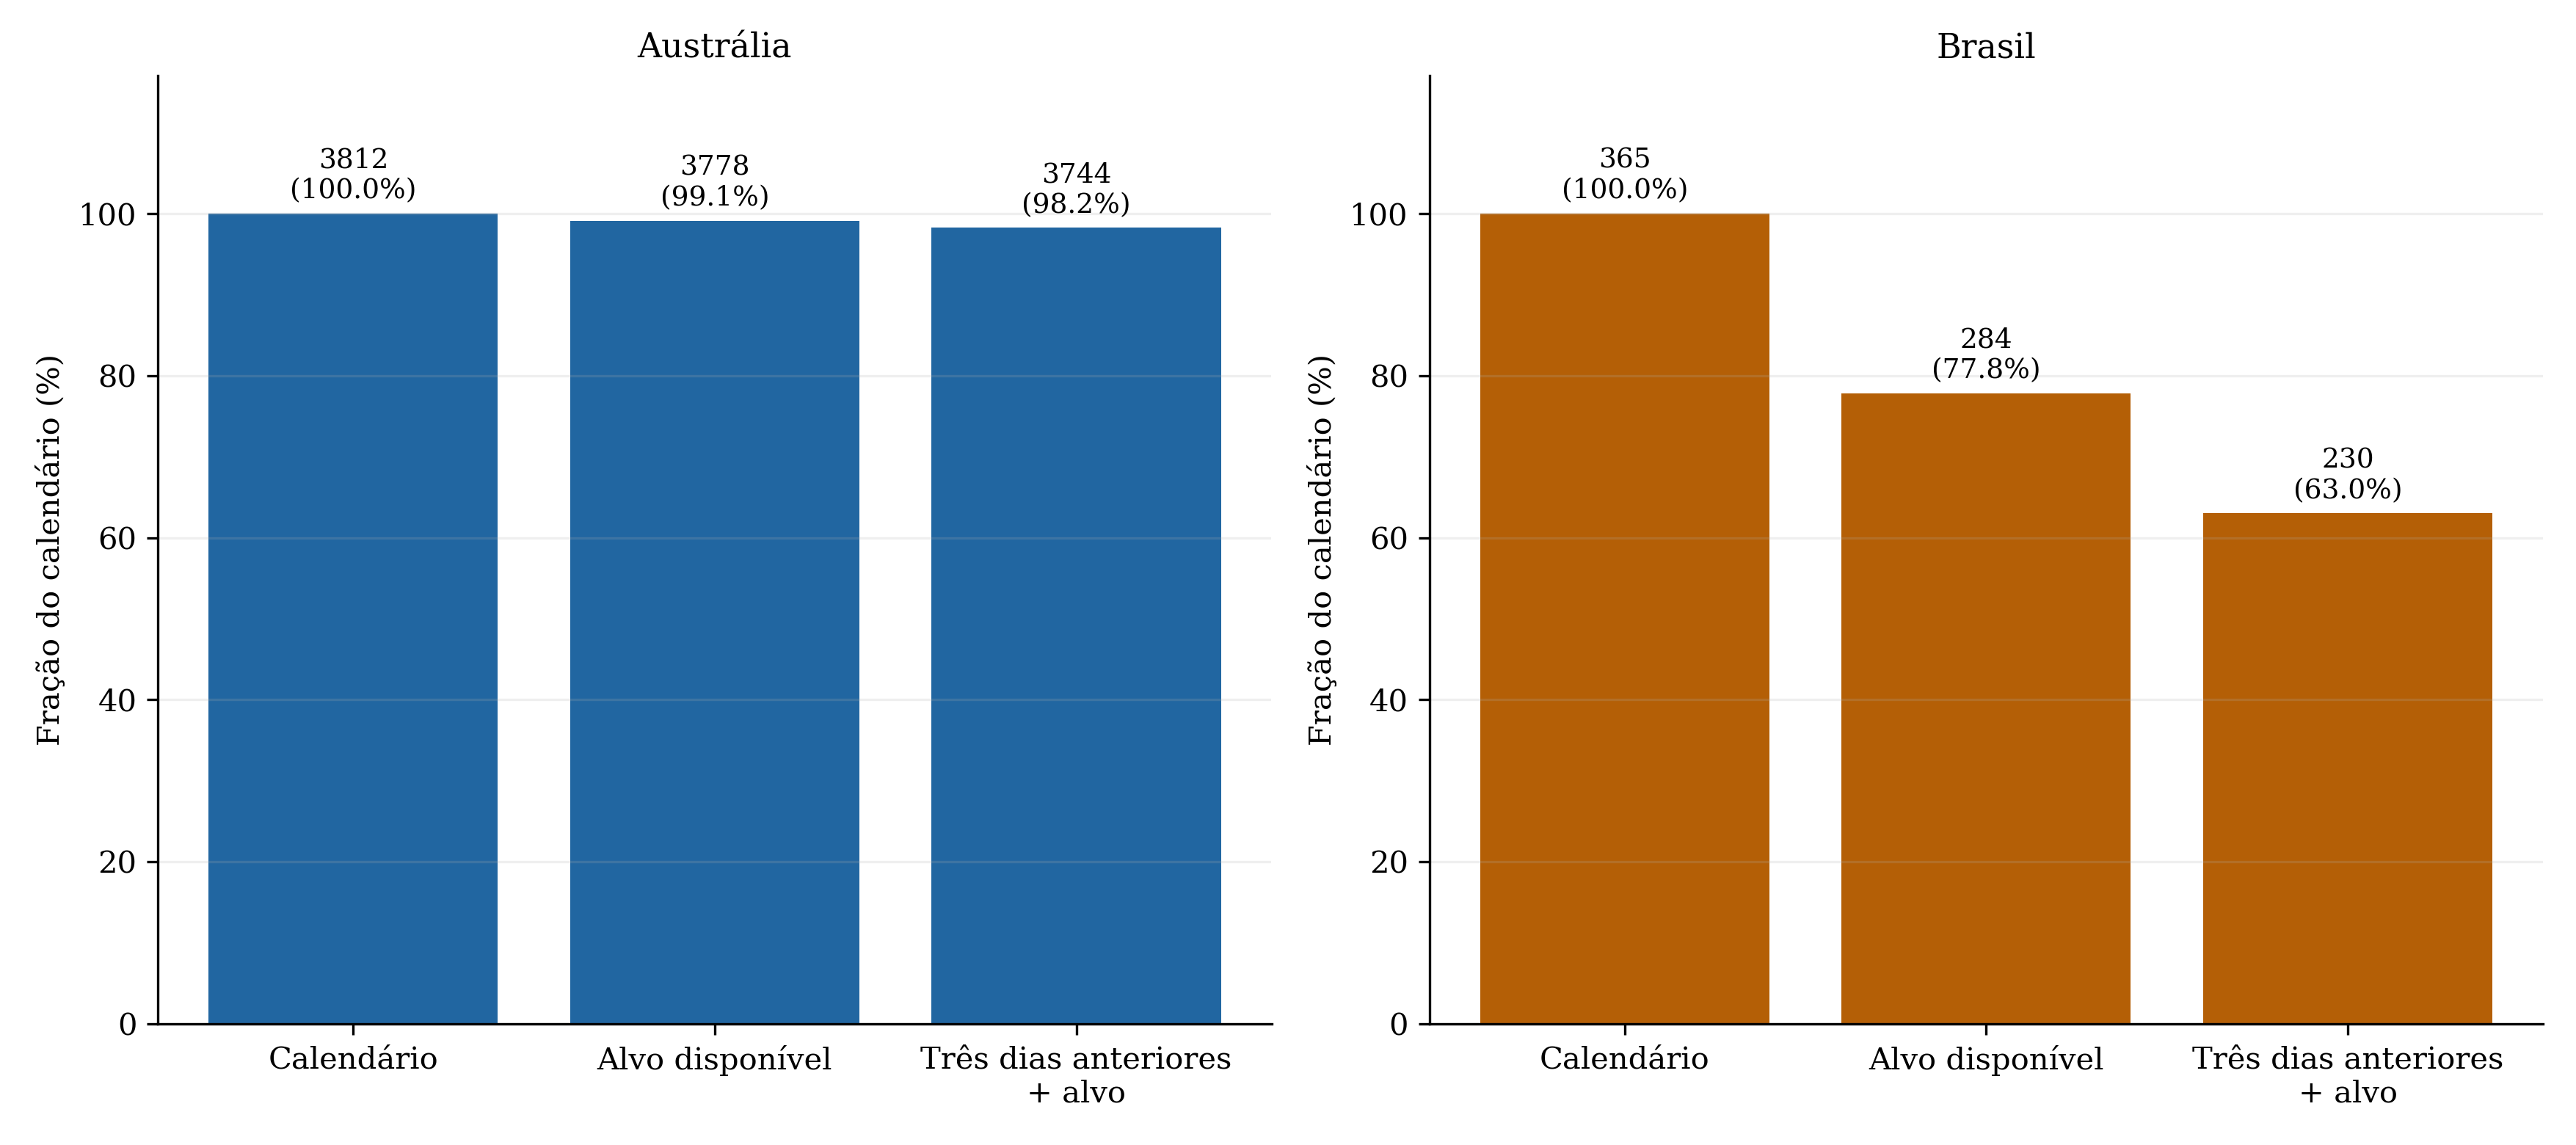

**Figura 3.3-07: Disponibilidade de alvos e de janelas consecutivas.** Disponibilidade relativa ao calendário diário em três etapas: calendário completo, alvo disponível e janela elegível com três dias anteriores consecutivos e um alvo. São obtidas 3744 janelas australianas e 230 brasileiras; estas se distribuem em 160, 26 e 44 janelas de treino, validação e teste. O calendário é preservado e as janelas não atravessam dias sem potência válida. Janelas sobrepostas apresentam dependência temporal.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

In [8]:
display(tabelas["funil_disponibilidade"])
display(tabelas["particoes"])
figura(7)

As partições brasileiras finais possuem 160 janelas de treino, 26 de validação e 44 de teste. As australianas disponíveis têm 3392 e 352 janelas de treino/validação. O ajuste conjunto Chronos balanceia o portfólio com uma seleção de 160 janelas australianas e 160 brasileiras, e não usa todas as janelas australianas em cada ajuste.

Cada janela da LSTM começa com estado recorrente reiniciado. Os pesos são compartilhados entre as amostras de treino, mas não se carrega estado temporal de um bloco para outro. Na avaliação de um passo, o histórico observado é atualizado em cada origem; não é uma previsão recursiva de todo o período de teste.

## 3.3.5 Normalização e padronização

**Normalização física por capacidade:**

[
P^{pu}=ar P/P_{nominal}^{AC}.
]

O projeto adota 24 kW para a Austrália e 1000 kW para o Brasil. São parâmetros que ainda requerem confirmação técnica definitiva da instalação/configuração associada ao arquivo. A divisão aproxima escalas de capacidade, mas não elimina diferenças de clima, tecnologia, disponibilidade ou construção do alvo.

**Padronização das MLP/LSTM brasileiras atuais:**

[
z_{x,j}=(x_j-mu_{j,treino})/sigma_{j,treino},qquad
z_y=(y-mu_{y,treino})/sigma_{y,treino}.
]

Médias e desvios populacionais (`ddof=0`) são ajustados exclusivamente nas **160 janelas brasileiras de treino**, considerando conjuntamente suas três posições históricas. Um dia presente em várias janelas aparece várias vezes no cálculo, conforme implementação. Validação e teste reutilizam os parâmetros, sem reajuste. O alvo tem parâmetros próprios.

As seis entradas históricas são potência, temperatura, umidade, GHI, seno e cosseno anuais. O calendário conhecido do alvo mantém a escala original [−1,1]. O cálculo anual considera 365 ou 366 dias. Vento e meteorologia futura observada não entram.

**Chronos diário atual:** recebe potência em p.u., meteorologia nas unidades físicas e calendário. Não usa o padronizador externo das redes locais; possui seu próprio processamento interno. O estudo anterior de transferência de MLP/LSTM usou outra versão da base e outro protocolo de escalas, que não devem ser atribuídos a este benchmark.

,variavel,media_treino,desvio_treino_ddof0
0,Active_Power,0.24246,0.04746
1,Weather_Temperature_Celsius,22.53554,1.77068
2,Weather_Relative_Humidity,61.98498,17.17260
3,Global_Horizontal_Radiation,228.20972,42.06502
4,dia_ano_sin,0.12453,0.76772
5,dia_ano_cos,-0.34218,0.52727
6,Alvo y (potência p.u.),0.24523,0.04659


,Domínio,Capacidade AC adotada (kW)
0,Austrália,24.00000
1,Brasil,1000.00000


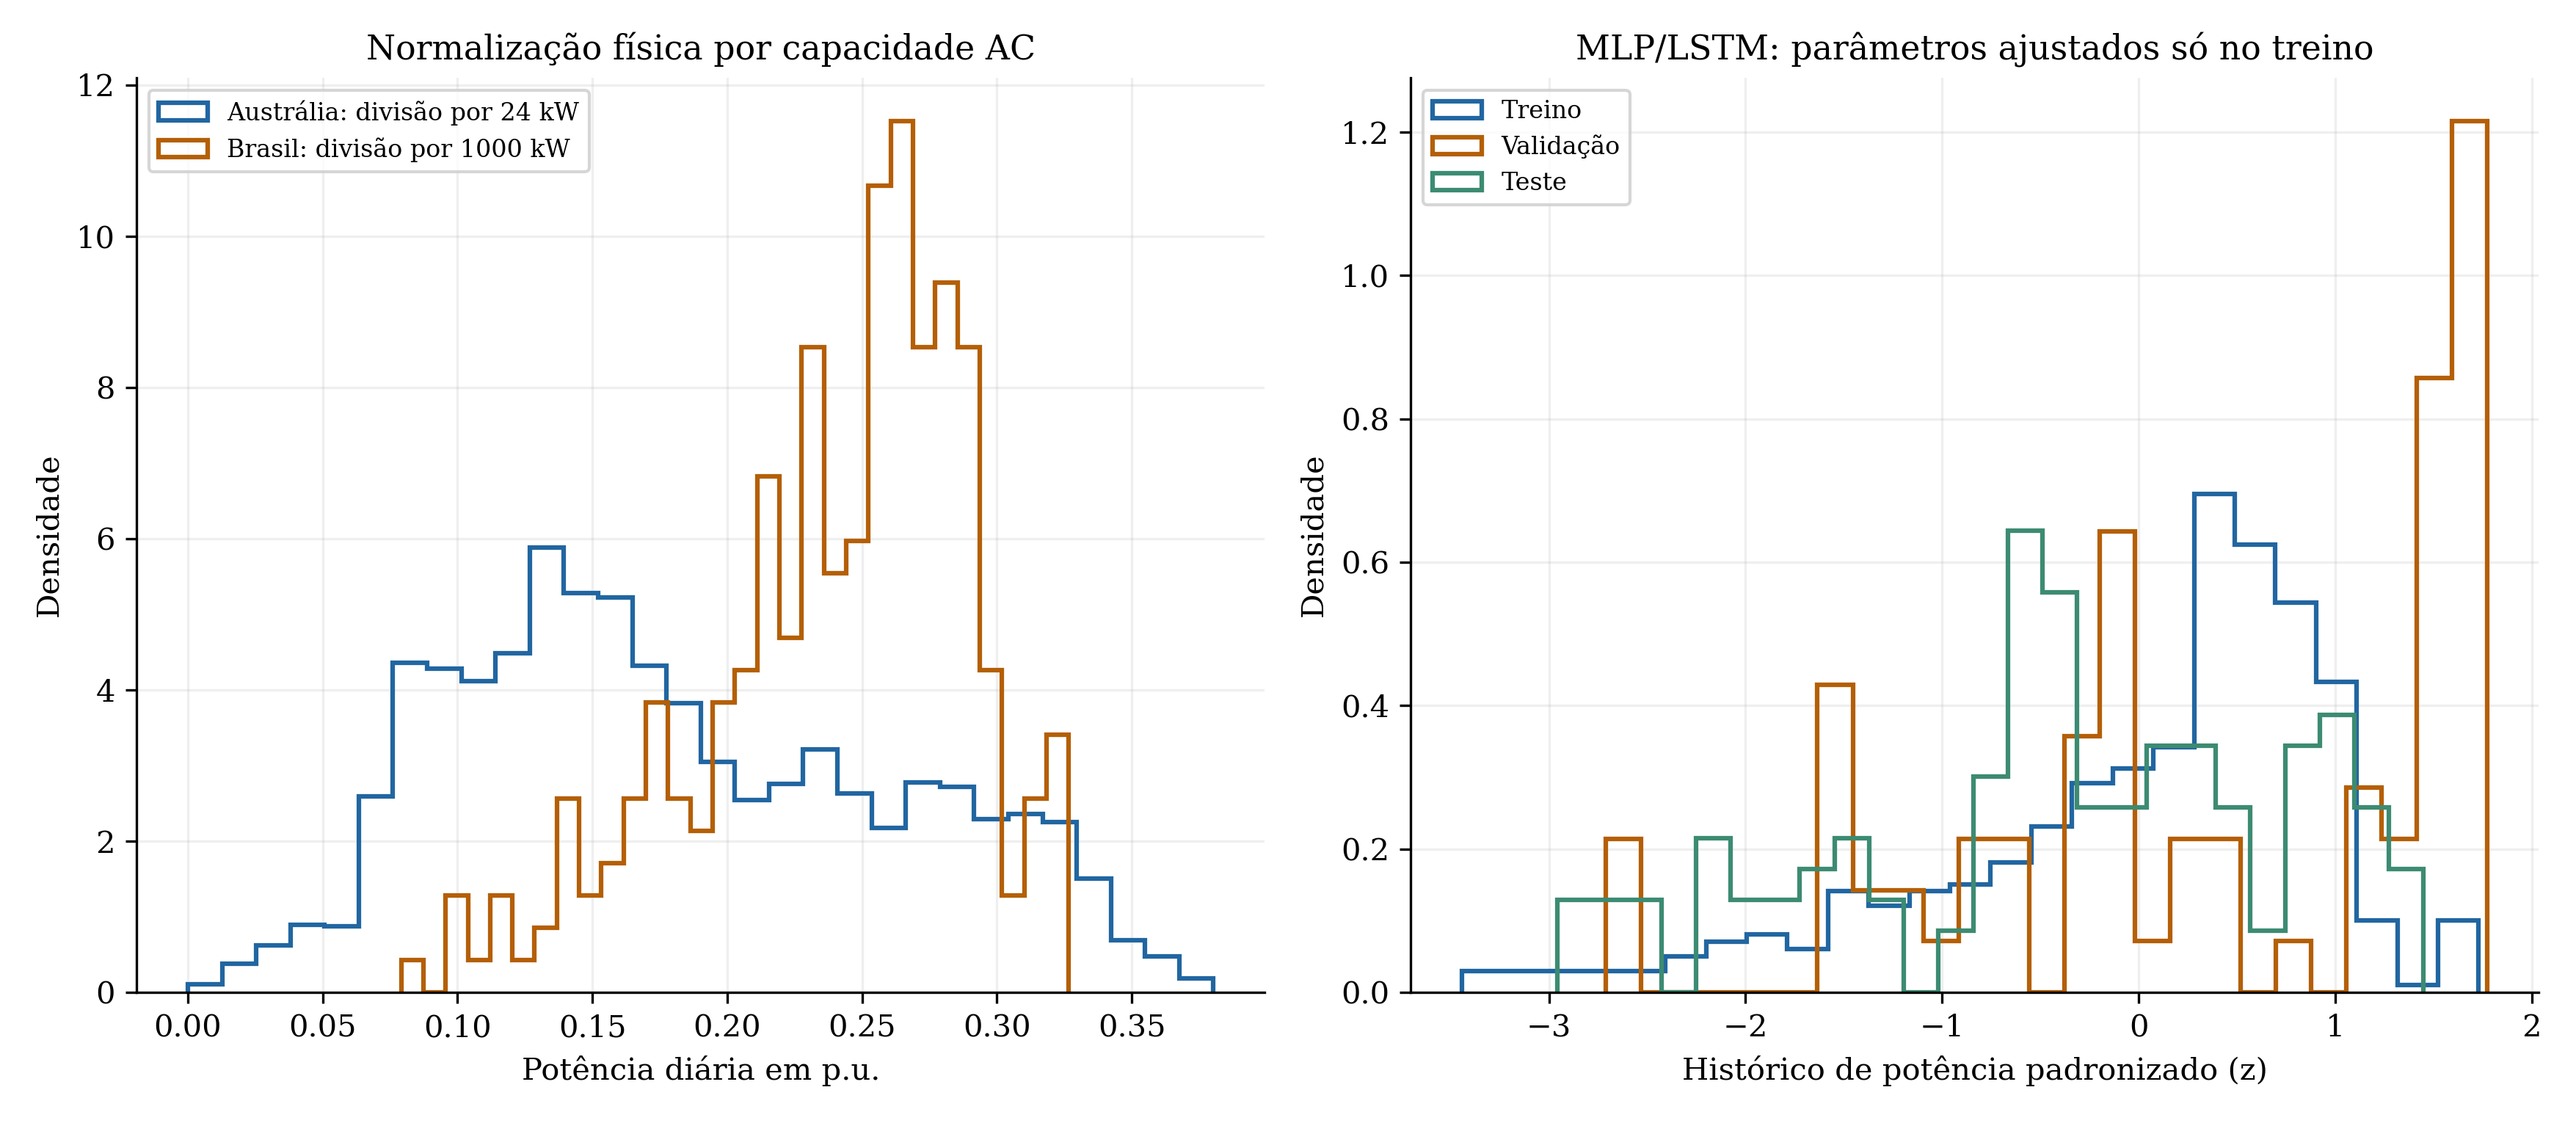

**Figura 3.3-08: Normalização física e padronização estatística.** À esquerda, distribuições da potência diária normalizada pelas capacidades AC adotadas de 24 kW e 1000 kW, respectivamente para Austrália e Brasil, sujeitas à confirmação documental. À direita, distribuições do histórico brasileiro após padronização pela média e pelo desvio padrão ajustados exclusivamente nas janelas de treino e mantidos na validação e no teste. Dias repetidos em janelas sobrepostas participam do ajuste. A padronização externa é utilizada nas MLP/LSTM locais; o Chronos recebe potência em p.u. e meteorologia em unidades físicas.

Fonte: elaboração própria com os arquivos e procedimentos identificados no manifesto.

In [9]:
display(tabelas["escalas_treino_brasil"])
cap = processamento["meta"]["capacidades_ac_kw"]
display(pd.DataFrame({"Domínio": ["Austrália", "Brasil"], "Capacidade AC adotada (kW)": [cap["australia"], cap["brasil"]]}))
# Verificação direta de média/desvio após transformação do histórico de treino.
x = np.asarray(processamento["janelas"]["treino"]["X"], dtype=float)
z = (x - np.asarray(processamento["escala"]["x_media"])) / np.asarray(processamento["escala"]["x_escala"])
np.testing.assert_allclose(z.mean(axis=(0,1)), 0, atol=1e-8)
np.testing.assert_allclose(z.std(axis=(0,1)), 1, atol=1e-8)
figura(8)

### Pontos a explicitar antes de fechar o texto

- A cobertura intradiária australiana não recebeu corte mínimo no protocolo atual. Uma eventual análise de sensibilidade deve ser declarada e exigir nova avaliação se alterar alvos.
- Capacidade nominal e fuso australiano precisam de confirmação documental final.
- Os limiares brasileiros de contador e os limites diários meteorológicos são escolhas deste conjunto, não padrões universais.
- A concordância de contadores não elimina erros comuns; a origem meteorológica é diferente entre os países.
- O trabalho é retrospectivo; disponibilidade operacional em tempo real da reanálise não foi demonstrada.

Essas ressalvas acompanham os resultados, mas não mudam os procedimentos reproduzidos aqui.

In [10]:
print("Tabelas e conferências:", processamento["tabelas_dir"])
print("Figuras PNG e PDF:", processamento["figuras"])
print("Legendas:", PASTA / "legendas_figuras.md")
print("Fontes e hashes:", PASTA / "manifesto.json")
print("Potência imputada?", processamento["meta"]["imputacao_potencia"])
print("Os dados e modelos existentes foram preservados.")

Tabelas e conferências: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\preprocessamento_diario\tabelas
Figuras PNG e PDF: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\preprocessamento_diario\figuras
Legendas: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\preprocessamento_diario\legendas_figuras.md
Fontes e hashes: C:\Users\camil\Documents\transfer-learning-energy-forecast-tcc\reports\tcc\preprocessamento_diario\manifesto.json
Potência imputada? False
Os dados e modelos existentes foram preservados.
